# Run 3: a one-day data gap in the wavelet analysis

Run 2's series (true sky envelope $M_c^2(t)$, seed 2026, 30 d) with a **hard gap from day 12.0 to 13.0**: the time series
is set to zero there, and the wavelet likelihood **leaves out** every 10-h time pixel that overlaps the gap plus one
buffer pixel on each side (the gap edges bias those by ~10%, [gap_check.py](gap_check.py)). That is 5 time pixels,
11.46–13.54 d (50 h). A likelihood block of 2 time pixels keeps $\nu = ({\rm kept\ pixels})\times n_g$ degrees of
freedom; blocks with nothing left are dropped (`WaveletLikelihood(time_mask=...)`).

Everything else (priors, sampler settings, seeds) is as in run 2, so **the only difference from run 2's wavelet run is
the gap**. The question: is the modulation still recovered, and how much wider do the posteriors get?

Compared quantity for the modulation: the **galactic brightness relative to the injection**, i.e. amplitude ×
spectral shape × $P_c(t)$ of each posterior sample divided by the injected one (the spectral shape averaged over
frequency with the weight of where the galaxy dominates; run-2 notebook §5b). 1 means recovered = injected.

Set `RERUN = True` to sample again (`python injection.py --tag run3 --injection sky --gap 12 13`, about 40 min, plus
`--k-trace` for the burn-in plot).

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import corner
import jax
import jax.numpy as jnp

ROOT = Path.cwd()
while not (ROOT / 'pyproject.toml').exists():
    ROOT = ROOT.parent
HERE = ROOT / 'data' / 'wavelet_injection'
sys.path.insert(0, str(HERE))
import injection as I
import diagnostics as D
from bahamas.wavelet.model import DAY
from bahamas.wavelet.sampler import modulation_draws, _sampled
from bahamas.wavelet.simulate import power_modulation

RERUN = False
GAP = (12.0, 13.0)
CFG3 = I.with_gap(GAP, buffer_pixels=1)
OUT = HERE / 'outputs' / 'run3'
CH = ['A', 'E']
C_TRUTH, C_NOGAP, C_NOGAP_L, C_GAP, C_GAP_L, C_MUTED = '#0b0b0b', '#2a78d6', '#86b6ef', '#eb6834', '#f5b48f', '#52514e'
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25, 'axes.spines.top': False,
                     'axes.spines.right': False, 'lines.linewidth': 1.5, 'legend.frameon': False})
amp_true, amp_ref = I.true_amp(), I.load_reference()['amp']

2026-10-17 09:33:42,734 - BAHAMAS - INFO - Using JAX backend.


2026-10-17 09:33:42,736 - BAHAMAS - INFO - np is from: jax.numpy


## 1. Data and the pixels the likelihood leaves out

run 3 series = run 2 series outside the gap: True; zero inside: True
left out: time pixels [28, 29, 30, 31, 32] = 11.46-13.54 d (50 h)
likelihood blocks: run 2 34, run 3 32; pixels used: run 2 283016, run 3 262206 (7.4% fewer)


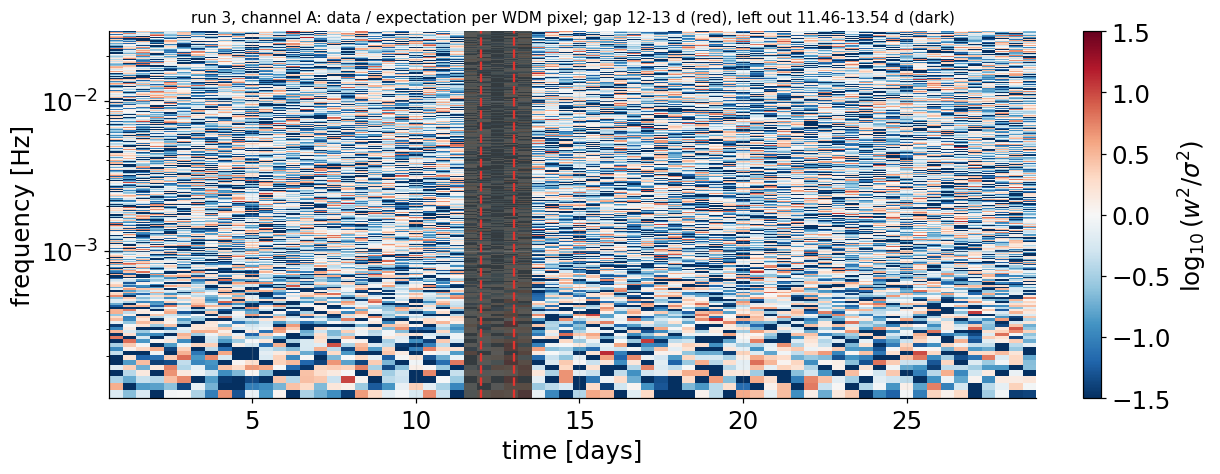

In [2]:
data2, inj = I.load_or_simulate('sky', 'run2')
like2, post2 = I.build_posterior(data2)
data3, _ = I.load_or_simulate('sky', 'run3', CFG3)
like3, post3 = I.build_posterior(data3, CFG3)
mask = I.gap_time_mask(data3, CFG3)
dT = data3.Nf * data3.dt
off = np.flatnonzero(~mask)
gap_lo, gap_hi = (data3.times[off[0]] - dT / 2) / DAY, (data3.times[off[-1]] + dT / 2) / DAY
x2, dt, t0 = I.load_timeseries('run2'); x3, _, _ = I.load_timeseries('run3')
t = t0 + np.arange(x3.shape[1]) * dt
g = (t >= GAP[0] * DAY) & (t < GAP[1] * DAY)
print(f"run 3 series = run 2 series outside the gap: {np.array_equal(x3[:, ~g], x2[:, ~g])}; zero inside: {np.all(x3[:, g] == 0)}")
print(f"left out: time pixels {off.tolist()} = {gap_lo:.2f}-{gap_hi:.2f} d ({(gap_hi - gap_lo) * 24:.0f} h)")
print(f"likelihood blocks: run 2 {len(like2.times)}, run 3 {len(like3.times)}; "
      f"pixels used: run 2 {like2.npixels}, run 3 {like3.npixels} ({100 * (1 - like3.npixels / like2.npixels):.1f}% fewer)")

# per-pixel data / expectation at the injection (true amplitude), channel A, masked columns shaded
names_w = [p.name for p in _sampled(post2.psd_params)]
theta_true = np.array([p.value for p in _sampled(post2.psd_params)], float)
theta_true[names_w.index('amp')] = amp_true
f = like2.eval_freqs
from bahamas.psd_strain import psd_galaxy as gal, psd_noise as noise
from bahamas.wavelet.sampler import _fill
vals = _fill(post2.psd_params, jnp.asarray(theta_true))
per_pixel = lambda s: np.asarray(jnp.reshape(s, (like2.npix, -1)) @ like2._weights)
Sg = per_pixel(gal.galactic_foreground(f, vals['galactic_DWD_time'], gen2=False))
Sn = per_pixel(noise.noise(f, vals['instr_noise'], tdi=0, gen2=False))
ti = like2.time_index
sig2 = (np.asarray(inj.P(data3.times[ti], 0))[:, None] * Sg[None] + Sn[None]) / (2 * data3.dt)
z = data3.w[0][ti][:, like2.pixels] ** 2 / sig2
te = np.append(data3.times[ti] - dT / 2, data3.times[ti][-1] + dT / 2) / DAY
fp = data3.freqs[like2.pixels]; dF = fp[1] - fp[0]
fe = np.append(fp - dF / 2, fp[-1] + dF / 2)
fig, ax = plt.subplots(figsize=(11, 4.2), constrained_layout=True)
from matplotlib.colors import TwoSlopeNorm
m = ax.pcolormesh(te, fe, np.log10(z).T, cmap='RdBu_r', norm=TwoSlopeNorm(vcenter=0, vmin=-1.5, vmax=1.5),
                  shading='flat', rasterized=True)
ax.axvspan(gap_lo, gap_hi, color='#3d3d3a', alpha=0.85, lw=0, label='left out of the likelihood')
for e in GAP:
    ax.axvline(e, color='#e3342f', ls='--', lw=1.5)
ax.set_yscale('log'); ax.set_xlabel('time [days]'); ax.set_ylabel('frequency [Hz]')
ax.set_title(f'run 3, channel A: data / expectation per WDM pixel; gap {GAP[0]:g}-{GAP[1]:g} d (red), '
             f'left out {gap_lo:.2f}-{gap_hi:.2f} d (dark)', fontsize=10)
fig.colorbar(m, ax=ax, label=r'$\log_{10}(w^2/\sigma^2)$')
fig.savefig(OUT / 'data_gap_mask.png', dpi=140)

## 2. Sampling and convergence (run 3)

In [3]:
res_path = OUT / 'chains.npz'
if RERUN or not res_path.exists():
    I.run('sky', 'run3', config=CFG3)
r3 = dict(np.load(res_path, allow_pickle=True))
r2 = dict(np.load(HERE / 'outputs' / 'run2' / 'chains.npz', allow_pickle=True))
nsteps, nw = int(r3['nsteps']), int(r3['nwalkers'])
print(f"runtime {float(r3['runtime_s']) / 60:.1f} min, {nsteps} steps x {nw} walkers (cold chain); acceptance "
      f"{np.mean(r3['acceptance_fraction']):.3f}, RJ acceptance {np.mean(r3['rj_acceptance_fraction']):.3f}\n")
D.report(r3, post3, np.array([5., 12.5, 15., 25.]) * DAY)
print()
for c in CH:
    for lab, r in (('run 2 (no gap)', r2), ('run 3 (gap)   ', r3)):
        K, p = r[f'mod_{c}_bayes_K'], r[f'mod_{c}_bayes_posterior']
        print(f"{c} {lab}: " + ' '.join(f'p(K={k})={q:.3f}' for k, q in zip(K, p) if q > 1e-3))

runtime 30.3 min, 6000 steps x 32 walkers (cold chain); acceptance 0.079, RJ acceptance 0.008



        quantity  tau_acf tau_batch      ESS  nsteps/tau
           alpha      2.0       7.5    25665       802.0
             amp      1.9       4.8    39748      1242.1
           fknee      1.8       5.5    34623      1082.0
             fr1      1.9       6.6    28994       906.1
             fr2      2.0       7.5    25639       801.2
               A      1.7       4.4    43611      1362.8
               P      1.7       3.8    50462      1576.9
         level_E      2.0       6.2    30832       963.5
             K_A      2.1       4.3    45050      1407.8
             K_E      1.8       3.4    55893      1746.6
           log L      2.9       8.0    24107       753.3
        P_A(5 d)      1.8       4.2    45673      1427.3
       P_A(12 d)      1.8       4.9    39310      1228.4
       P_A(15 d)      1.9       6.9    27737       866.8
       P_A(25 d)      1.7       3.7    51889      1621.5
        P_E(5 d)      1.8       4.8    40131      1254.1
       P_E(12 d)      1.7      

### Exploration of K, including the burn-in

As in runs 1 and 2: the sampler rerun with the burn-in stored (`--k-trace`), cold walkers only; the dotted line is
the posterior mode of K (the true envelope is not a finite sum of atoms).

32 walkers x 4 temperatures; 2000 burn-in + 6000 stored steps; rerun reproduces chains.npz: True
A: every walker off K = 0 from step 29; K range burn-in 0-5, stored 1-8; mean K last 500 burn-in 1.73, stored 1.80
E: every walker off K = 0 from step 3; K range burn-in 0-8, stored 1-8; mean K last 500 burn-in 1.95, stored 1.97


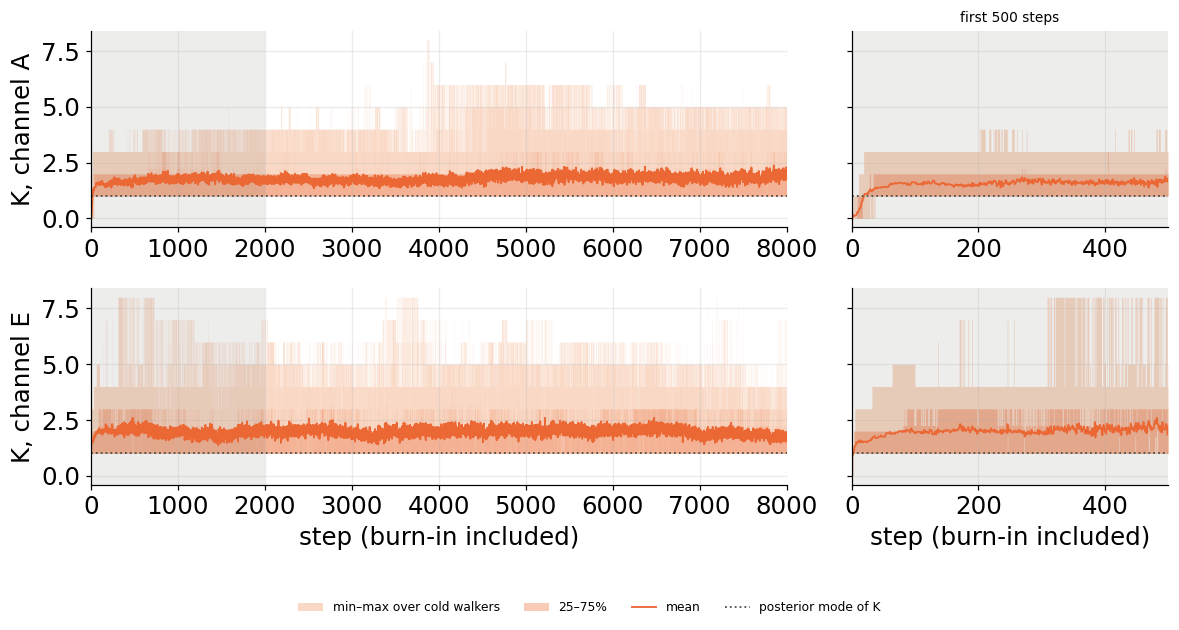

In [4]:
kt = dict(np.load(I.k_trace_path('run3')))
burn = int(kt['burnin'])
print(f"{int(kt['nwalkers'])} walkers x {int(kt['ntemps'])} temperatures; {burn} burn-in + {int(kt['nsteps'])} stored steps; "
      f"rerun reproduces chains.npz: {bool(kt.get('matches_chains'))}")
fig, axes = plt.subplots(2, 2, figsize=(11, 5.6), sharey='row', gridspec_kw={'width_ratios': [2.2, 1]})
for row, c in enumerate(CH):
    K = kt[f'K_{c}'][:, 0].astype(float)
    step = np.arange(1, len(K) + 1)
    lo, hi = K.min(1), K.max(1)
    q25, q75 = np.percentile(K, [25, 75], axis=1)
    mode = int(r3[f'mod_{c}_bayes_K'][np.argmax(r3[f'mod_{c}_bayes_posterior'])])
    for ax, sl, xmax in zip(axes[row], [slice(None), slice(0, 500)], [len(K), 500]):
        ax.fill_between(step[sl], lo[sl], hi[sl], step='mid', color=C_GAP_L, alpha=0.5, lw=0, label='min–max over cold walkers')
        ax.fill_between(step[sl], q25[sl], q75[sl], step='mid', color=C_GAP, alpha=0.35, lw=0, label='25–75%')
        ax.plot(step[sl], K[sl].mean(1), color=C_GAP, lw=1.2, label='mean')
        ax.axhline(mode, color=C_MUTED, ls=':', lw=1.2, label='posterior mode of K')
        ax.axvspan(0, min(burn, xmax), color=C_MUTED, alpha=0.10, lw=0)
        ax.set_xlim(0, xmax)
    axes[row, 0].set_ylabel(f'K, channel {c}')
    print(f"{c}: every walker off K = 0 from step {np.argmax(lo >= 1) + 1}; K range burn-in {int(lo[:burn].min())}-"
          f"{int(hi[:burn].max())}, stored {int(lo[burn:].min())}-{int(hi[burn:].max())}; mean K last 500 burn-in "
          f"{K[burn - 500:burn].mean():.2f}, stored {K[burn:].mean():.2f}")
for ax in axes[1]:
    ax.set_xlabel('step (burn-in included)')
axes[0, 1].set_title('first 500 steps', fontsize=9)
fig.legend(*axes[0, 0].get_legend_handles_labels(), fontsize=8, ncol=4, loc='lower center', bbox_to_anchor=(0.5, -0.04))
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(OUT / 'K_trace_burnin.png', dpi=150, bbox_inches='tight')

## 3. Spectral parameters: gap vs no gap

param       truth |   no gap: median, 90% width |   gap: median, 90% width | width gap/no gap | shift / sigma(no gap)
alpha       1.800 |       1.8324       0.2002 |       1.8445     0.2038 |            1.018 | +0.21
amp               |     -43.4010       0.2472 |     -43.3918     0.2186 |            0.884 | +0.11
fknee      -2.177 |      -2.1785       0.0061 |      -2.1788     0.0059 |            0.964 | -0.16
fr1        -2.429 |      -2.4189       0.0246 |      -2.4163     0.0261 |            1.061 | +0.35
fr2        -3.488 |      -3.5451       0.2364 |      -3.5475     0.2357 |            0.997 | -0.03
A           2.400 |       2.4427       0.1181 |       2.4666     0.1280 |            1.084 | +0.66
P           7.900 |       7.9040       0.0433 |       7.9001     0.0433 |            1.000 | -0.30
level_E           |       1.1430       0.4995 |       1.0305     0.6345 |            1.270 | -0.75


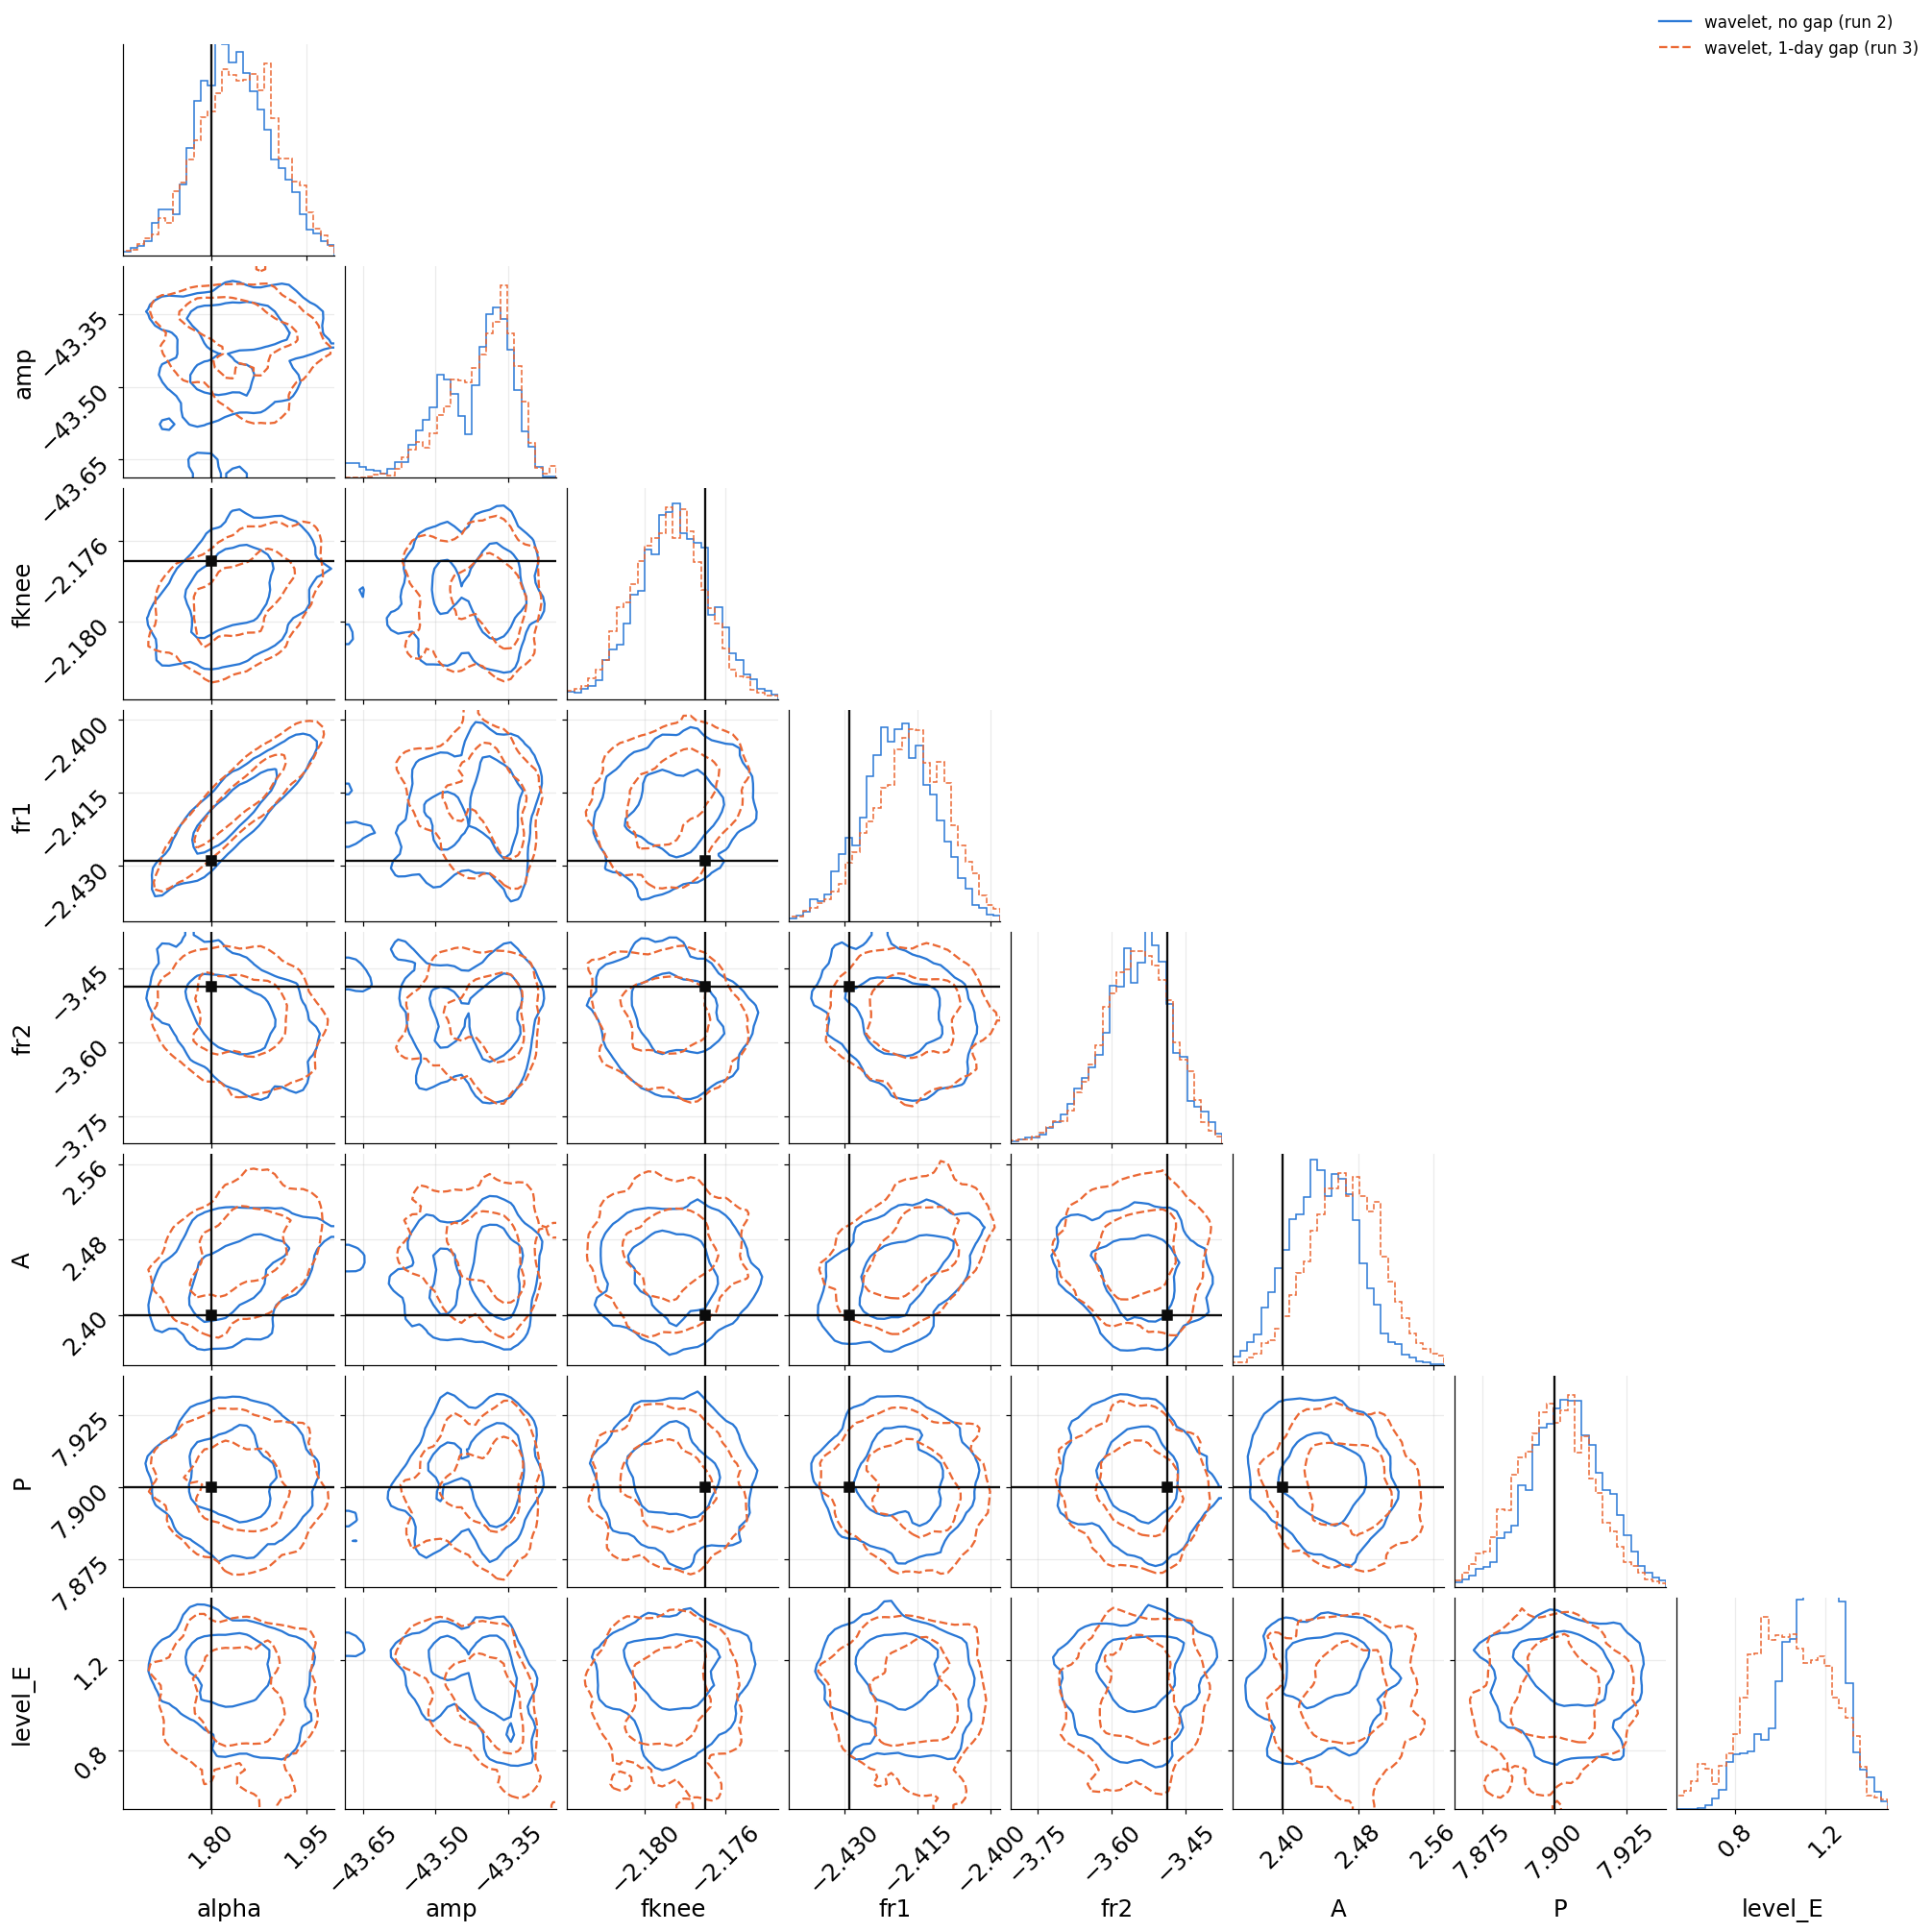

In [5]:
shared = ['alpha', 'amp', 'fknee', 'fr1', 'fr2', 'A', 'P', 'level_E']
names = [str(n).split(':')[-1] for n in r2['psd_names']]
ch2 = np.column_stack([r2['psd_chain'][:, names.index(k)] for k in shared])
ch3 = np.column_stack([r3['psd_chain'][:, names.index(k)] for k in shared])
truth_src = {p['name']: p['injected'] for s in I.og_sources().values() for p in s}
truths = [truth_src.get(k) if k not in ('amp', 'level_E') else None for k in shared]
rng_ = [tuple(np.percentile(np.r_[ch2[:, i], ch3[:, i]], [0.2, 99.8])) for i in range(len(shared))]
def kw(ls='-'):
    return dict(range=rng_, bins=30, smooth=1.0, plot_datapoints=False, plot_density=False, levels=(0.5, 0.9),
                max_n_ticks=3, labelpad=0.12, hist_kwargs={'density': True, 'linestyle': ls}, contour_kwargs={'linestyles': ls})
fig = corner.corner(ch2, labels=shared, color=C_NOGAP, **kw())
corner.corner(ch3, fig=fig, color=C_GAP, truths=truths, truth_color=C_TRUTH, **kw('--'))
fig.legend(handles=[plt.Line2D([], [], color=C_NOGAP, label='wavelet, no gap (run 2)'),
                    plt.Line2D([], [], color=C_GAP, ls='--', label='wavelet, 1-day gap (run 3)')], loc='upper right', fontsize=11)
fig.savefig(OUT / 'corner_gap_vs_nogap.png', dpi=110, bbox_inches='tight')

print(f"{'param':8s} {'truth':>8s} | {'no gap: median, 90% width':>27s} | {'gap: median, 90% width':>24s} | width gap/no gap | shift / sigma(no gap)")
for i, k in enumerate(shared):
    q2, q3 = np.percentile(ch2[:, i], [5, 50, 95]), np.percentile(ch3[:, i], [5, 50, 95])
    tr = '' if truths[i] is None else f'{truths[i]:8.3f}'
    print(f"{k:8s} {tr:>8s} | {q2[1]:12.4f} {q2[2] - q2[0]:12.4f} | {q3[1]:12.4f} {q3[2] - q3[0]:10.4f} | "
          f"{(q3[2] - q3[0]) / (q2[2] - q2[0]):16.3f} | {(q3[1] - q2[1]) / ch2[:, i].std():+.2f}")

## 4. The modulation: recovered galactic brightness, gap vs no gap

For each of 1000 posterior samples: (its amplitude × its spectral shape × its $P_c(t)$) / (the injected ones), then the
median and the 50% / 90% bands over the samples at each time. 0 on the plot = recovered equals injected. The dark band
is the 50 h left out of the run-3 likelihood; there the run-3 curve is an interpolation by the atoms.

A:
   no gap (run 2)  90% width: 6.1% away from the gap, up to 5.9% within 1 d of it;  median offset +1.5%;  truth inside 90%: 90% of the span, 100% near the gap
   gap (run 3)     90% width: 6.1% away from the gap, up to 6.2% within 1 d of it;  median offset +1.2%;  truth inside 90%: 91% of the span, 100% near the gap
E:
   no gap (run 2)  90% width: 5.4% away from the gap, up to 5.4% within 1 d of it;  median offset -1.3%;  truth inside 90%: 100% of the span, 100% near the gap
   gap (run 3)     90% width: 5.5% away from the gap, up to 5.8% within 1 d of it;  median offset -1.4%;  truth inside 90%: 100% of the span, 100% near the gap


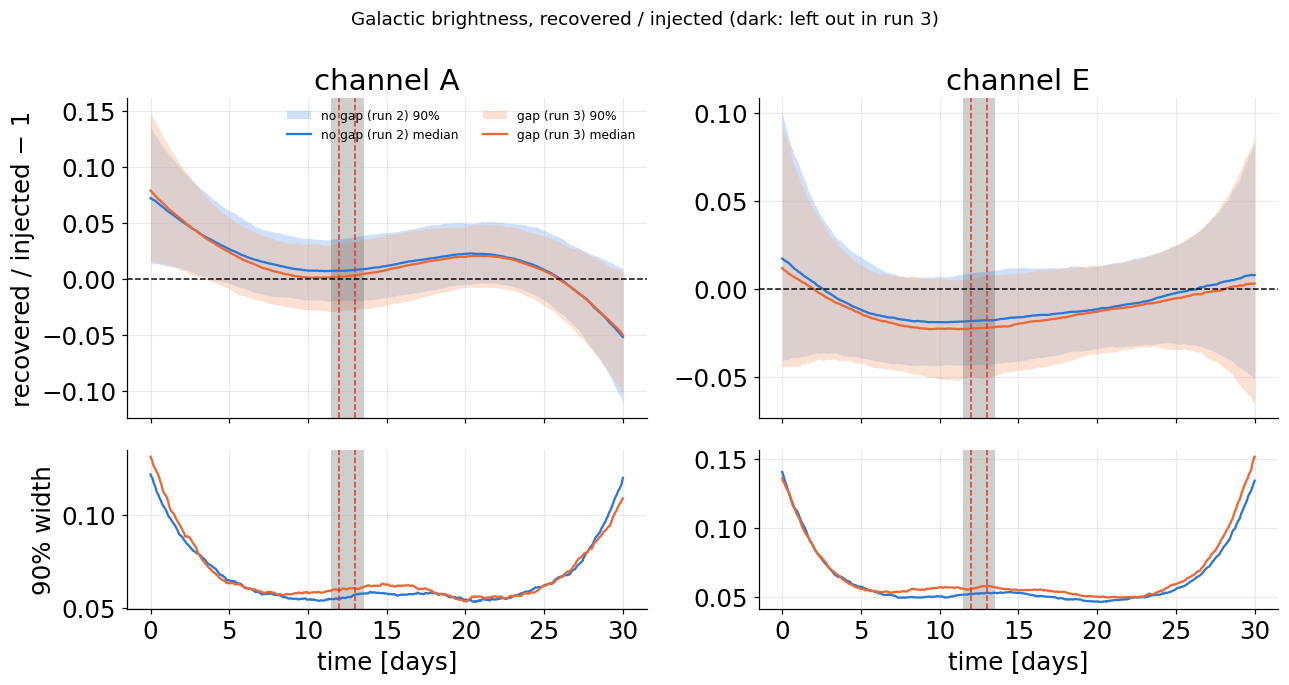

In [6]:
t_fine = np.linspace(0, data2.Nt * dT, 600)
P_true = np.stack([np.asarray(power_modulation(I.sky_params(), t_fine, c)) for c in (0, 1)])
theta_inj = np.array([p.value for p in _sampled(post2.psd_params)], float)          # amp = amp_ref
Sg0, Sn0, _ = post2.spectra(jnp.asarray(theta_inj)); Sg0, Sn0 = np.asarray(Sg0), np.asarray(Sn0)
ok = Sg0 > 1e-3 * Sg0.max()
W = np.stack([np.where(ok, np.asarray(like2.nu) * (Sg0 / (Sg0 + Sn0[c])) ** 2, 0.) for c in (0, 1)])
W /= W.sum(1, keepdims=True)
spec_batch = jax.jit(jax.vmap(lambda th: post2.spectra(th)[0]))

def brightness(r, post):
    # (ndraw, 2, nt): amplitude x shape x P_c relative to the injection, for 1000 posterior draws
    idx = np.random.default_rng(0).choice(len(r['psd_chain']), size=1000, replace=False)
    P = 10 ** (amp_ref - amp_true) * modulation_draws(post, r, t_fine, nsamples=1000, seed=0)   # 10^(amp - amp_true) P_c
    th = np.array(r['psd_chain'][idx], float); th[:, names_w.index('amp')] = theta_inj[names_w.index('amp')]
    R = np.where(ok, np.asarray(spec_batch(jnp.asarray(th))) / np.where(ok, Sg0, 1.), 0.) @ W.T
    return P * R[:, :, None] / P_true[None]

B = {'no gap (run 2)': brightness(r2, post2), 'gap (run 3)': brightness(r3, post3)}
td = t_fine / DAY
t_lo, t_hi = float(like2.times[0]) / DAY, float(like2.times[-1]) / DAY
inside = (td >= t_lo) & (td <= t_hi)
near = (td >= gap_lo - 1) & (td <= gap_hi + 1)
far = inside & ~((td >= gap_lo - 4) & (td <= gap_hi + 4))
fig, axes = plt.subplots(2, 2, figsize=(12, 6.4), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
summary = {}
for i, c in enumerate(CH):
    ax, axw = axes[:, i]
    summary[c] = {}
    for (lab, b), cl, cd in zip(B.items(), (C_NOGAP_L, C_GAP_L), (C_NOGAP, C_GAP)):
        q = np.percentile(b[:, i], [5, 25, 50, 75, 95], axis=0)
        ax.fill_between(td, q[0] - 1, q[4] - 1, color=cl, alpha=0.4, lw=0, label=f'{lab} 90%')
        ax.plot(td, q[2] - 1, color=cd, label=f'{lab} median')
        axw.plot(td, q[4] - q[0], color=cd, label=lab)
        wdt = q[4] - q[0]
        summary[c][lab] = dict(w_far=np.median(wdt[far]), w_near=np.max(wdt[near]), off=np.median(q[2][inside]) - 1,
                               cov=np.mean(((q[0] <= 1) & (1 <= q[4]))[inside]), cov_near=np.mean(((q[0] <= 1) & (1 <= q[4]))[near]))
    for a in (ax, axw):
        a.axvspan(gap_lo, gap_hi, color='#3d3d3a', alpha=0.25, lw=0)
        for e in GAP:
            a.axvline(e, color='#e3342f', ls='--', lw=1)
    ax.axhline(0, color=C_TRUTH, ls='--', lw=1)
    ax.set_title(f'channel {c}')
    axw.set_xlabel('time [days]')
    print(f"{c}:")
    for lab, s in summary[c].items():
        print(f"   {lab:15s} 90% width: {100 * s['w_far']:.1f}% away from the gap, up to {100 * s['w_near']:.1f}% within 1 d of it;"
              f"  median offset {100 * s['off']:+.1f}%;  truth inside 90%: {100 * s['cov']:.0f}% of the span, "
              f"{100 * s['cov_near']:.0f}% near the gap")
axes[0, 0].legend(fontsize=8, ncol=2)
axes[1, 0].set_ylabel('90% width')
axes[0, 0].set_ylabel('recovered / injected − 1')
fig.suptitle('Galactic brightness, recovered / injected (dark: left out in run 3)', fontsize=12)
fig.tight_layout()
fig.savefig(OUT / 'modulation_gap_vs_nogap.png', dpi=150)

### Recovered modulation, data-covered times only

The recovered $P_c(t)$ of run 3 against the injected envelope $M_c^2(t)$, drawn only where the likelihood has data: the
left-out span is blank. Each sample's $P_c(t)$ is put on the injected scale with its amplitude and spectral shape
(recovered brightness / injected brightness × $M_c^2(t)$), so the dashed curve is the truth.

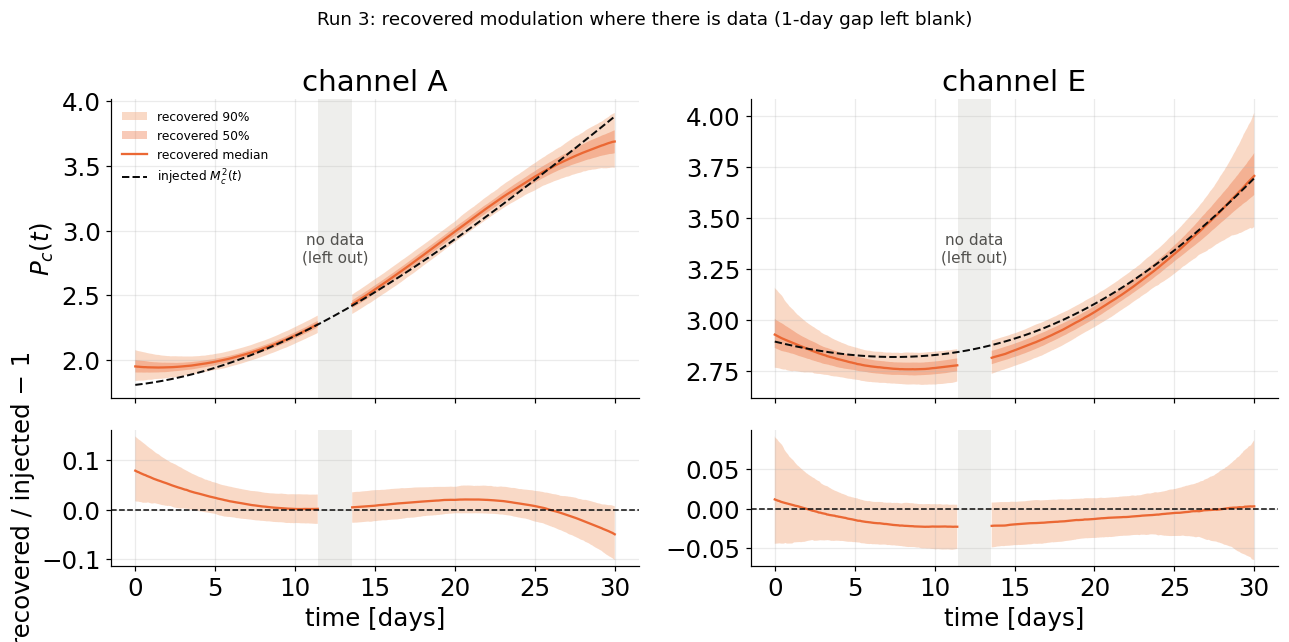

In [7]:
b4 = B['gap (run 3)']                                    # recovered / injected brightness, (ndraw, 2, nt)
has_data = ~((td >= gap_lo) & (td <= gap_hi))
fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True, gridspec_kw={'height_ratios': [2.2, 1]})
for i, c in enumerate(CH):
    ax, axr = axes[:, i]
    q = np.percentile(b4[:, i] * P_true[i], [5, 25, 50, 75, 95], axis=0)
    q = np.where(has_data, q, np.nan)                       # nothing drawn in the gap
    ax.fill_between(td, q[0], q[4], color=C_GAP_L, alpha=0.5, lw=0, label='recovered 90%')
    ax.fill_between(td, q[1], q[3], color=C_GAP, alpha=0.35, lw=0, label='recovered 50%')
    ax.plot(td, q[2], color=C_GAP, label='recovered median')
    ax.plot(td, P_true[i], color=C_TRUTH, ls='--', lw=1.3, label=r'injected $M_c^2(t)$')
    r = np.where(has_data, np.percentile(b4[:, i], [5, 50, 95], axis=0), np.nan)
    axr.fill_between(td, r[0] - 1, r[2] - 1, color=C_GAP_L, alpha=0.5, lw=0)
    axr.plot(td, r[1] - 1, color=C_GAP)
    axr.axhline(0, color=C_TRUTH, ls='--', lw=1)
    for a in (ax, axr):
        a.axvspan(gap_lo, gap_hi, color='#eeeeec', lw=0, zorder=0)
    ax.text((gap_lo + gap_hi) / 2, 0.5, 'no data\n(left out)', transform=ax.get_xaxis_transform(), ha='center',
            va='center', color=C_MUTED, fontsize=10)
    ax.set_title(f'channel {c}')
    axr.set_xlabel('time [days]')
axes[0, 0].set_ylabel(r'$P_c(t)$')
axes[1, 0].set_ylabel('recovered / injected − 1')
axes[0, 0].legend(fontsize=8, loc='upper left')
fig.suptitle('Run 3: recovered modulation where there is data (1-day gap left blank)', fontsize=12)
fig.tight_layout()
fig.savefig(OUT / 'modulation_recovered.png', dpi=150)

### Shape only

Each sample's $P_c(t)$ divided by its own mean over the analysed span (amplitude and spectrum drop out).

A shape, no gap (run 2): median 90% width 4.3%, truth inside 100%
A shape, gap (run 3): median 90% width 4.5%, truth inside 96%
E shape, no gap (run 2): median 90% width 3.9%, truth inside 100%
E shape, gap (run 3): median 90% width 4.0%, truth inside 100%


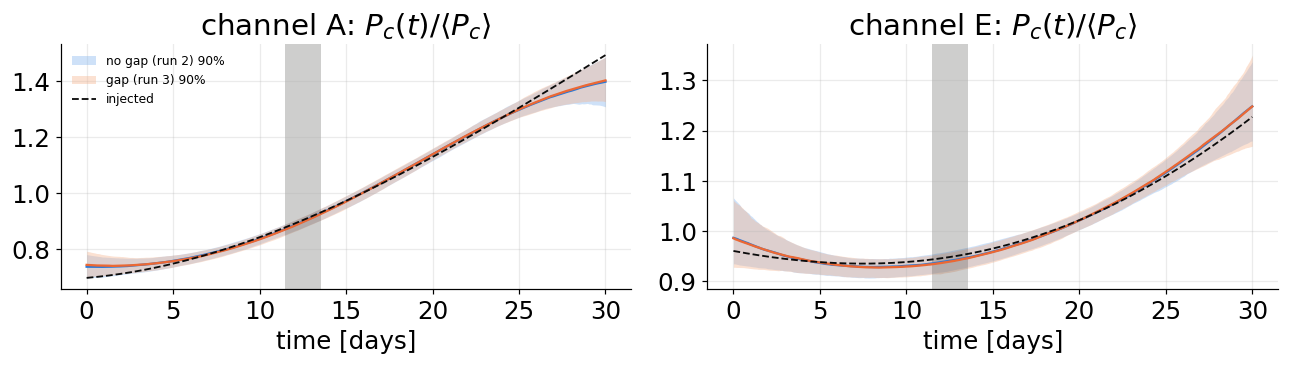

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharex=True)
S_true = P_true / P_true[:, inside].mean(1, keepdims=True)
for i, (ax, c) in enumerate(zip(axes, CH)):
    for (lab, r, post), cl, cd in zip([('no gap (run 2)', r2, post2), ('gap (run 3)', r3, post3)], (C_NOGAP_L, C_GAP_L), (C_NOGAP, C_GAP)):
        Pd = modulation_draws(post, r, t_fine, nsamples=1000, seed=0)[:, i]
        S = Pd / Pd[:, inside].mean(1, keepdims=True)
        q = np.percentile(S, [5, 50, 95], axis=0)
        ax.fill_between(td, q[0], q[2], color=cl, alpha=0.4, lw=0, label=f'{lab} 90%')
        ax.plot(td, q[1], color=cd)
        print(f"{c} shape, {lab}: median 90% width {100 * np.median((q[2] - q[0])[inside]):.1f}%, "
              f"truth inside {100 * np.mean(((q[0] <= S_true[i]) & (S_true[i] <= q[2]))[inside]):.0f}%")
    ax.plot(td, S_true[i], color=C_TRUTH, ls='--', lw=1.2, label='injected')
    ax.axvspan(gap_lo, gap_hi, color='#3d3d3a', alpha=0.25, lw=0)
    ax.set_title(f'channel {c}: $P_c(t)/\\langle P_c\\rangle$'); ax.set_xlabel('time [days]')
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT / 'shape_gap_vs_nogap.png', dpi=150)

## 5. Summary

The numbers above are collected in [reports/WAVELET_INJECTION_RUN3.md](../../reports/WAVELET_INJECTION_RUN3.md).